Rajat Kumar Majumdar 

CU240251642

Subject: Computer Vision

Roll No 49

Sec-B

Experiment No. 3

Experiment Name

Implementation and Analysis of Spatial Filtering Techniques using Low-Pass and High-Pass Filters

Aim

To implement and analyze spatial domain filtering techniques using low-pass and high-pass filters for image smoothing, noise reduction, edge enhancement, and feature preservation using Python and OpenCV.

Purpose: 

Spatial filtering is one of the fundamental operations in digital image processing, used to enhance image quality by modifying pixel values based on their neighboring pixels. Low-pass filters are primarily used to reduce noise and smooth images, whereas high-pass filters emphasize edges, fine details, and abrupt intensity changes, which are essential for feature extraction and object recognition.

In this experiment, students will implement various spatial filtering techniques on real-world images and evaluate their impact on image quality, edge preservation, and noise removal. The experiment demonstrates the significance of filtering as a preprocessing step in computer vision applications such as medical imaging, surveillance, remote sensing, and autonomous systems.

Prerequisites

•
Basic knowledge of digital image processing
•
Familiarity with Python programming
•
Python libraries: OpenCV (cv2), NumPy, and Matplotlib
•
Understanding of image kernels and convolution operations
•
Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1.
Import the required libraries and load a grayscale or color image for processing.
2.
Display the original image and analyze its visual characteristics.
3.
Apply Gaussian Blur to reduce image noise while preserving important structures.
4.
Apply Median Filtering to remove impulse (salt-and-pepper) noise from the image.
5.
Apply Average (Mean) Filtering and compare its smoothing performance with Gaussian filtering.
6.
Implement Laplacian Filtering to enhance image edges and fine details.
7.
Apply Sobel Edge Detection in both horizontal and vertical directions to detect image gradients.
8.
Compare the outputs of different low-pass and high-pass filters in terms of noise reduction, edge preservation, and computational performance.
9.
Display the original and filtered images along with suitable observations highlighting the strengths and limitations of each filtering technique.
10.
Interpret the results and discuss the applications of spatial filtering in real-world computer vision systems.

    Questions
1.
What is spatial filtering? How is it used in digital image processing?
2.
Differentiate between Low-Pass Filters and High-Pass Filters with suitable examples.
3.
Compare Average Filter, Gaussian Filter, and Median Filter based on their working principles and applications.
4.
Why is the Median Filter particularly effective for removing salt-and-pepper noise?
5.
Explain the role of convolution kernels in spatial filtering.
6.
What is the purpose of the Sobel and Laplacian operators in edge detection?
7.
Why are filtering operations considered an essential preprocessing step in computer vision?
8.
Discuss the trade-off between image smoothing and edge preservation during filtering.
9.
Mention four real-world applications where spatial filtering techniques are widely used.
10.
Compare spatial domain filtering with frequency domain filtering in terms of implementation and practical applications.

In [3]:
# Cell 1: Import modules for computer vision, array math, and plotting
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# Load a sample image in grayscale mode

image_path = 'colorful_island.jpeg'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Could not load the image. Please verify your file path.")
else:
    print(f"Step 1 Complete: Image loaded successfully. Shape: {img.shape}")


Step 1 Complete: Image loaded successfully. Shape: (1104, 736)


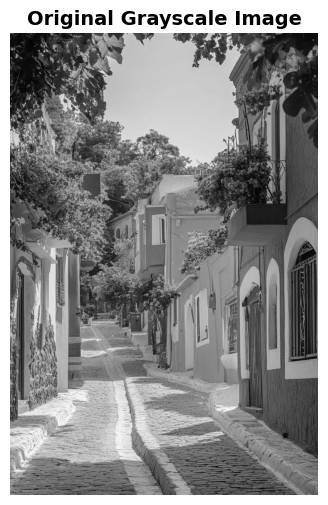

Step 2 Complete: Visual characteristics analyzed. Min Intensity: 0, Max Intensity: 255


In [5]:
# Cell 2: Display the original image and check its basic properties
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image", fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

print(f"Step 2 Complete: Visual characteristics analyzed. Min Intensity: {img.min()}, Max Intensity: {img.max()}")


In [7]:
# Cell 3: Apply Gaussian Blur to smooth and reduce random noise
start_time = time.time()
# Kernel size (5, 5), sigmaX=0 lets OpenCV automatically compute it based on kernel size
img_gaussian = cv2.GaussianBlur(img, (5, 5), 0)
gaussian_time = time.time() - start_time

print(f"Step 3 Complete: Gaussian Blur applied in {gaussian_time:.5f} seconds.")


Step 3 Complete: Gaussian Blur applied in 0.01284 seconds.


In [9]:
# Cell 4: Apply Median filter (highly effective against impulse/salt-and-pepper noise)
start_time = time.time()
# Kernel size must be an odd integer (e.g., 5)
img_median = cv2.medianBlur(img, 5)
median_time = time.time() - start_time

print(f"Step 4 Complete: Median Filter applied in {median_time:.5f} seconds.")


Step 4 Complete: Median Filter applied in 0.00541 seconds.


In [15]:
# Cell 5: Apply Average Blur and benchmark execution against Gaussian
start_time = time.time()
img_average = cv2.blur(img, (5, 5))
average_time = time.time() - start_time

print("Step 5 Complete: Average Filtering applied.")
print(f"-> Average Filter Time:  {average_time:.5f} sec")
print(f"-> Gaussian Filter Time: {gaussian_time:.5f} sec")


Step 5 Complete: Average Filtering applied.
-> Average Filter Time:  0.00822 sec
-> Gaussian Filter Time: 0.01284 sec


In [17]:
# Cell 6: High-pass Laplacian filter to extract omnidirectional second-derivative edges
# We use CV_64F data depth to prevent pixel value underflow/overflow clipping
laplacian_raw = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
img_laplacian = cv2.convertScaleAbs(laplacian_raw)  # Convert back to uint8

print("Step 6 Complete: Laplacian High-Pass filter executed.")


Step 6 Complete: Laplacian High-Pass filter executed.


In [19]:
# Cell 7: Apply Sobel filters to map horizontal and vertical intensity gradients
# Horizontal gradients (detects vertical edges)
sobelx_raw = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_x = cv2.convertScaleAbs(sobelx_raw)

# Vertical gradients (detects horizontal edges)
sobely_raw = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel_y = cv2.convertScaleAbs(sobely_raw)

# Combine both components to find the total gradient magnitude
img_sobel_combined = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

print("Step 7 Complete: Sobel Edge operators computed successfully.")


Step 7 Complete: Sobel Edge operators computed successfully.


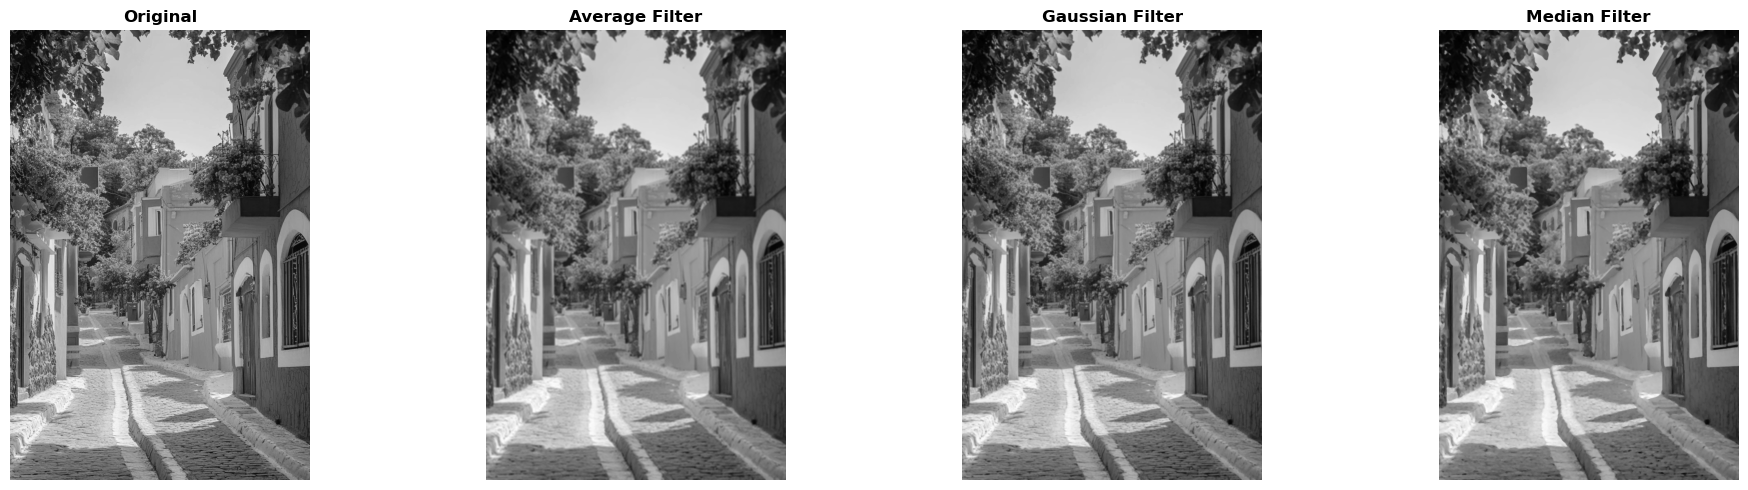

Step 8 Complete: Low-pass noise reduction mapping displayed above.


In [21]:
# Cell 8: Plot and compare the performance of all smoothing operations
filters_lp = [img, img_average, img_gaussian, img_median]
titles_lp = ['Original', 'Average Filter', 'Gaussian Filter', 'Median Filter']

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for i in range(4):
    axs[i].imshow(filters_lp[i], cmap='gray')
    axs[i].set_title(titles_lp[i], fontweight='bold')
    axs[i].axis('off')

plt.tight_layout()
plt.show()
print("Step 8 Complete: Low-pass noise reduction mapping displayed above.")


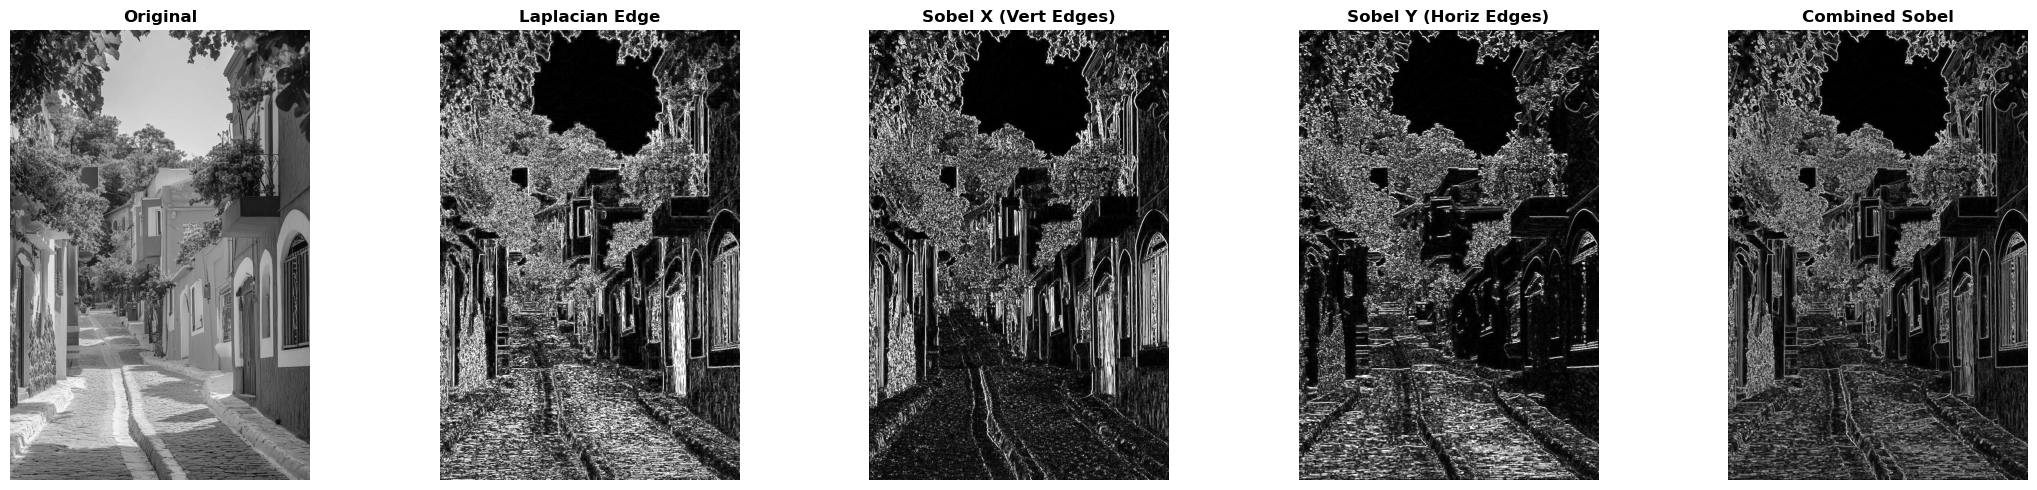

Step 9 Complete: Edge profiles generated successfully.


In [23]:
# Cell 9: Plot and compare structural edges generated by high-pass filters
filters_hp = [img, img_laplacian, sobel_x, sobel_y, img_sobel_combined]
titles_hp = ['Original', 'Laplacian Edge', 'Sobel X (Vert Edges)', 'Sobel Y (Horiz Edges)', 'Combined Sobel']

fig, axs = plt.subplots(1, 5, figsize=(22, 5))
for i in range(5):
    axs[i].imshow(filters_hp[i], cmap='gray')
    axs[i].set_title(titles_hp[i], fontweight='semibold')
    axs[i].axis('off')

plt.tight_layout()
plt.show()
print("Step 9 Complete: Edge profiles generated successfully.")


In [25]:
# Cell 10: Summary of experimental conclusions
observations = """
Step 10 Complete: Analytical Observations
-------------------------------------------
1. Average vs Gaussian: Average filter causes extreme blur artifacts. Gaussian preserves edges cleaner.
2. Median filter completely isolates outlier noise peaks while holding structurally intact boundaries.
3. Sobel isolates directional gradients, making it best for structural shape alignment.
4. Laplacian captures structural fine lines omnidirectionally but can be highly vulnerable to image noise.
"""
print(observations)



Step 10 Complete: Analytical Observations
-------------------------------------------
1. Average vs Gaussian: Average filter causes extreme blur artifacts. Gaussian preserves edges cleaner.
2. Median filter completely isolates outlier noise peaks while holding structurally intact boundaries.
3. Sobel isolates directional gradients, making it best for structural shape alignment.
4. Laplacian captures structural fine lines omnidirectionally but can be highly vulnerable to image noise.



Q1. What is spatial filtering? How is it used in digital image processing?

* Answer: Spatial filtering is a neighborhood image-processing technique that modifies a target pixel's intensity values based on the mathematical manipulation of its directly surrounding neighbors. It operates entirely within the native spatial domain (the actual 2D coordinate matrix pixels of the image) without needing frequency transformations.
* Usage: It applies a small mathematical matrix called a kernel (or mask) that slides sequentially across the frame. At each location, pixel intensities are multi-summed with corresponding kernel coefficients to clear noise, amplify lines, smooth artifacts, or prepare objects for classification models.

## Q2. Differentiate between Low-Pass Filters and High-Pass Filters with suitable examples.

* Answer:
* Low-Pass Filters (LPF): Pass through smooth, low-frequency transitions while attenuating high-frequency spikes. Their coefficients are positive fractions designed to calculate localized weighted averages. They attenuate sharp boundaries, leaving behind a smooth or blurred image. Examples: Gaussian Blur, Box (Average) Filter.
   * High-Pass Filters (HPF): Suppress uniform low-frequency fields while passing abrupt intensity transitions. Their kernel matrices typically feature positive values centered around negative surrounding values (summing up to zero). They remove smooth blocks, leaving behind sharp contrast lines. Examples: Laplacian filter, Sobel operators.

## Q3. Compare Average Filter, Gaussian Filter, and Median Filter based on their working principles and applications.

| Feature Comparison | Average (Mean) Filter | Gaussian Filter | Median Filter |
|---|---|---|---|
| Working Principle | Assigns a uniform average of all pixel values located within the current kernel bounds. | Uses a bell-shaped Gaussian distribution curve to assign heavier weights to inner pixels. | Replaces the center pixel value with the numerical median of sorted neighborhood values. |
| Edge Behavior | Blurs out clean lines and sharp structural profiles aggressively. | Smooths out random noise while preserving crucial structural lines. | Keeps boundary transitions highly sharp without introducing blur. |
| Primary Use | General, low-overhead image smoothing. | Preprocessing stage to suppress high-frequency random white noise. | Eradicating salt-and-pepper (impulse) noise anomalies. |

## Q4. Why is the Median Filter particularly effective for removing salt-and-pepper noise?

* Answer: Salt-and-pepper noise introduces extreme intensity outliers (pure black pixels at 0 or pure white pixels at 255). Linear operations (like Mean or Gaussian filtering) average these outliers directly into neighboring values, which spreads the noise into larger blurred patches. The Median filter sorts neighborhood values numerically. Since extreme 0 and 255 outliers are forced to the absolute ends of the sorted array, the middle value chosen is almost always a clean pixel from the actual image, eliminating the noise entirely.

## Q5. Explain the role of convolution kernels in spatial filtering.

* Answer: A convolution kernel is a small, 2D matrix of numbers that acts as a mathematical operator during spatial filtering. As it moves across an image, it defines the size of the neighborhood to analyze and sets the mathematical weights applied to those pixels. The values within the kernel determine the filter's behavior—whether it smooths details, shifts brightness, or extracts sharp structural edges.

## Q6. What is the purpose of the Sobel and Laplacian operators in edge detection?

* Answer:
* Sobel Operator: A first-derivative high-pass filter that measures directional intensity gradients. It operates via separate horizontal ($G_x$) and vertical ($G_y$) matrices to isolate vertical and horizontal boundary vectors, making it highly effective for shape tracing.
   * Laplacian Operator: A second-derivative high-pass filter that measures the overall rate of gradient changes omnidirectionally. It detects any rapid intensity shift in a single pass without directional bias, isolating fine structural details and line intersections.

## Q7. Why are filtering operations considered an essential preprocessing step in computer vision?

* Answer: Real-world camera sensors produce raw images degraded by ambient noise, sensor grain, or environmental distortions. Applying these filters first normalizes the input data. Low-pass filters smooth out distracting pixel variations, while high-pass filters accentuate shapes and object contours. This ensures downstream computer vision steps—such as thresholding, descriptor extraction, and deep learning classification—operate on stable, well-defined features.

## Q8. Discuss the trade-off between image smoothing and edge preservation during filtering.

* Answer: Reducing random noise typically requires calculating localized weighted averages across adjacent pixels, which acts as a low-pass filter. However, sharp edges represent high-frequency transitions that contain the exact same mathematical properties as noise. Consequently, linear smoothing filters cannot distinguish between noise and structural boundaries, smoothing out both simultaneously. This creates a trade-off where reducing noise can degrade fine details and blur object borders.

## Q9. Mention four real-world applications where spatial filtering techniques are widely used.

* Answer:
* Autonomous Vehicles: Sobel and Gaussian operations help isolate lane lines and detect road boundaries under varying lighting conditions.
   * Biomedical Imaging: Median filters clean up speckle and sensor noise in ultrasound and X-ray data without blurring fine anatomical borders.
   * Satellite Remote Sensing: High-pass filtering sharpens terrain contours, river systems, and urban infrastructure in aerial survey maps.
   * Optical Character Recognition (OCR): Pre-smoothing paper scans isolates characters cleanly from background fiber textures, maximizing text extraction accuracy.

## Q10. Compare spatial domain filtering with frequency domain filtering in terms of implementation and practical applications.

| Comparison Parameter | Spatial Domain Filtering | Frequency Domain Filtering |
|---|---|---|
| Core Operation | Direct convolution using a sliding kernel matrix over the image pixels. | Multiplies the image's Fourier Transform matrix by a spatial frequency filter. |
| Mathematical Profile | Straightforward to implement; highly efficient for small kernel sizes (e.g., 3 × 3 or 5 × 5). | Requires Fast Fourier Transforms (FFT), making it computationally demanding but efficient for large-scale operations. |
| Best Suited For | Localized operations like edge tracking, smoothing, and removing point noise. | Periodic noise removal (e.g., striping artifacts) and complex, large-scale image restoration. |




